<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Task_2P_Bylhah_Mugotitsa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIG788 – Task 2P: Clustering and PCA
**Student:** Bylhah Mugotitsa  
**Unit:** SIG788 – Engineering AI Solutions  
**Datasets:** Obesity (UCI), TCGA Gene Expression (PANCAN HiSeq 801×20531)  




---
# PART A: Lesson Review and Reflection

## A1. Clustering and Unsupervised Learning

### Concept 1: K-Means Clustering

K-Means is an iterative algorithm that partitions n data points into k non-overlapping clusters. It starts by placing k centroids (either randomly or via k-means++), assigns each point to its nearest centroid by Euclidean distance, then moves each centroid to the mean of its assigned points. These two steps repeat until assignments stop changing.

**Why it matters:** Clustering is the primary tool for discovering hidden groupings in unlabelled data. In healthcare, K-Means can segment patients by clinical features to identify sub-populations that respond differently to treatments — without needing prior diagnoses. In retail, it segments customers by purchase behaviour.

**Practical example:** In this task, K-Means is applied to the Obesity dataset (16 features, 2111 samples) to discover body-composition and lifestyle groupings without using the class label. The algorithm finds structure that may cut across the seven clinical obesity categories.

---

### Concept 2: The Elbow Method and Silhouette Coefficient

Choosing the right number of clusters k is one of the most important — and difficult — decisions in clustering. The **Elbow Method** plots Within-Cluster Sum of Squares (WCSS/inertia) against k; the "elbow" where improvement slows suggests a good k. The **Silhouette Coefficient** (−1 to +1) measures how similar each point is to its own cluster versus the nearest other cluster; higher = better.

**Why it matters:** An incorrect k produces either over-fragmented or merged clusters that hide real structure. The silhouette score provides an objective, data-driven criterion that does not require ground-truth labels.

**Practical example:** For the Obesity dataset, silhouette scores across k = 2 to 11 peak at k = 10, even though there are only 7 clinical classes. This tells us the feature space has finer-grained natural groupings than the clinical taxonomy suggests.

---

## A2. Dimensionality Reduction and PCA

### Concept 3: Principal Component Analysis (PCA)

PCA is a linear dimensionality reduction technique that finds the directions (principal components) of maximum variance in the data. Each principal component is an eigenvector of the data covariance matrix, ordered by its eigenvalue (the amount of variance it captures). Projecting data onto the first k components retains the most information possible in k dimensions.

**Why it matters:** Many real-world datasets have hundreds or thousands of features. Feeding all of them to a model is slow, prone to overfitting, and often hurts performance due to the curse of dimensionality. PCA compresses features while retaining the most discriminative variation.

**Practical example:** The gene expression dataset has 20,531 gene features for 801 cancer samples. Applying PCA reduces this to 3 components (27.1% variance) that already show clear visual separation of five cancer types in a 3D scatter plot, with no labels required.

---

### Concept 4: Explained Variance and Cumulative Variance

The proportion of variance explained by each principal component tells us how much information it captures from the original data. Cumulative explained variance shows how many components are needed to retain, say, 90% of total information.

**Why it matters:** Explained variance guides the decision of how many components to retain. Retaining too few components discards discriminative information; retaining too many defeats the purpose of dimensionality reduction. A scree plot visualises the diminishing returns of adding more components.

**Practical example:** For the gene expression data, PC1 explains 10.54%, PC2 explains 8.75%, and PC3 explains 7.81%. The cumulative total is 27.10%. While this seems modest, it is remarkable for 20,531-dimensional data

---

## A3. Applying Clustering and PCA to Data Analytics

Clustering reveals hidden groupings in data that are not evident from summary statistics. In a patient dataset, K-Means might identify a subgroup with high BMI but low physical activity and poor diet, a cluster that shares a similar risk profile even if their clinical diagnoses differ. This is far more useful than simply counting how many patients fall into predefined BMI categories, because it lets clinicians design targeted interventions for each natural group.

Dimensionality reduction complements clustering by stripping away noise and redundancy before the clustering algorithm runs. High-dimensional data often contains many correlated features that slow computation and mislead distance metrics. PCA projects data onto orthogonal axes so that Euclidean distance in the reduced space better reflects genuine similarity.

A domain where both are essential is cancer genomics. RNA-Seq data produces tens of thousands of gene expression measurements per patient. PCA first reduces this to a manageable number of components capturing the dominant transcriptional programs. K-Means then clusters patients in this reduced space, potentially uncovering molecular subtypes that correspond to different prognoses or drug sensitivities.

---
# PART B: Problem Solving Practical Task

In [1]:
# ── Import all required libraries ─────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             davies_bouldin_score)
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
print('Libraries loaded.')

Libraries loaded.


## B1. Data Preparation and Encoding

In [2]:
# ── Load Obesity dataset ──────────────────────────────────────────────────────
# Dataset: UCI Obesity Levels (Estimation of Obesity Levels Based On Eating Habits and
# Physical Condition). 2111 samples, 16 features + 1 class label.
from google.colab import files
uploaded = files.upload()

Saving obesity.csv to obesity.csv


In [4]:
df_raw = pd.read_csv('obesity.csv')
print('Raw shape:', df_raw.shape)
print('\nClass distribution (NObeyesdad — will be removed):')
print(df_raw['NObeyesdad'].value_counts())

# Remove class label before clustering (unsupervised task)
y_labels = df_raw['NObeyesdad'].copy()
df = df_raw.drop('NObeyesdad', axis=1).copy()

print('\nFeature types:')
print(df.dtypes)

Raw shape: (2111, 17)

Class distribution (NObeyesdad — will be removed):
NObeyesdad
Normal_Weight          427
Obesity_Type_I         405
Obesity_Type_III       334
Obesity_Type_II        297
Insufficient_Weight    241
Overweight_Level_II    209
Overweight_Level_I     198
Name: count, dtype: int64

Feature types:
Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
dtype: objec

In [5]:
# ── Encoding strategy ─────────────────────────────────────────────────────────
#
# 1. BINARY ENCODING (yes/no columns): map yes→1, no→0
#    Chosen because there are only two categories with no ordering ambiguity.
#    Columns: family_history_with_overweight, FAVC, SMOKE, SCC
#
# 2. ORDINAL ENCODING (ordered categories): assign integer ranks
#    CAEC (food between meals): no < Sometimes < Frequently < Always
#    CALC (alcohol consumption): no < Sometimes < Frequently < Always
#    Chosen because these categories have a natural ordering — encoding as
#    integers preserves that ranking, which distance metrics can use.
#    One-hot encoding would destroy the ordering information.
#
# 3. ONE-HOT ENCODING (nominal, no ordering):
#    Gender (Male/Female), MTRANS (5 transport types)
#    Chosen because these categories have no natural order. Using integer codes
#    would imply Walking > Automobile numerically, which is meaningless and
#    would bias distance calculations toward an arbitrary ordering.
#
# 4. STANDARD SCALING: applied to all numeric features after encoding
#    so no single feature dominates Euclidean distance due to scale.

# --- Binary encoding ---
binary_cols = ['family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC']
for col in binary_cols:
    df[col] = (df[col] == 'yes').astype(int)
print('Binary encoded:', binary_cols)

# --- Ordinal encoding ---
ordinal_map = {'CAEC': ['no','Sometimes','Frequently','Always'],
               'CALC': ['no','Sometimes','Frequently','Always']}
for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True).codes
    print(f'Ordinal encoded {col}: {dict(enumerate(order))}')

# --- One-hot encoding ---
nominal_cols = ['Gender', 'MTRANS']
df = pd.get_dummies(df, columns=nominal_cols, dtype=int)
print('\nOHE applied to:', nominal_cols)

# --- Standard scaling ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
print(f'\nFinal feature matrix: {X_scaled.shape}')
print('Features:', list(df.columns))

Binary encoded: ['family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC']
Ordinal encoded CAEC: {0: 'no', 1: 'Sometimes', 2: 'Frequently', 3: 'Always'}
Ordinal encoded CALC: {0: 'no', 1: 'Sometimes', 2: 'Frequently', 3: 'Always'}

OHE applied to: ['Gender', 'MTRANS']

Final feature matrix: (2111, 21)
Features: ['Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'Gender_Female', 'Gender_Male', 'MTRANS_Automobile', 'MTRANS_Bike', 'MTRANS_Motorbike', 'MTRANS_Public_Transportation', 'MTRANS_Walking']


**Encoding discussion:**

The three encoding strategies reflect the underlying nature of each variable:

- **Binary encoding** is appropriate for true yes/no variables, no information is lost and the representation is minimal (one column, two values).
- **Ordinal encoding** preserves the ranked structure of variables like food consumption frequency. A model using Euclidean distance correctly interprets 'Sometimes' (1) as closer to 'Frequently' (2) than to 'Always' (3). One-hot encoding would break this relationship.
- **One-hot encoding** for Gender and MTRANS prevents the model from treating arbitrary code differences (e.g., Automobile=0 vs Walking=4) as meaningful magnitudes.

A poor encoding choice would make the clustering algorithm treat 'Walking' and 'Bike' as numerically adjacent even if their health implications are very different from 'Automobile'. This would distort cluster assignments in ways that do not reflect genuine similarity.

## B2. Determining Optimal Number of Clusters

In [6]:
# ── Silhouette analysis for k = 2 to 11 ──────────────────────────────────────
k_range = range(2, 12)
sil_scores = []
inertias   = []

for k in k_range:
    # Run K-Means with k-means++ init and 10 restarts for stable estimate
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labs = km.fit_predict(X_scaled)
    # Sample 500 points for speed — still statistically reliable for 2111 samples
    sil = silhouette_score(X_scaled, labs, sample_size=500, random_state=42)
    sil_scores.append(sil)
    inertias.append(km.inertia_)
    print(f'k={k:2d}:  silhouette={sil:.4f}   inertia={km.inertia_:,.0f}')

optimal_k = list(k_range)[np.argmax(sil_scores)]
print(f'\nOptimal k = {optimal_k}  (silhouette = {max(sil_scores):.4f})')
print(f'Actual number of obesity classes in dataset = 7')

k= 2:  silhouette=0.1227   inertia=39,154
k= 3:  silhouette=0.1333   inertia=37,158
k= 4:  silhouette=0.1434   inertia=35,110
k= 5:  silhouette=0.1327   inertia=33,505
k= 6:  silhouette=0.1344   inertia=31,371
k= 7:  silhouette=0.1455   inertia=29,801
k= 8:  silhouette=0.1440   inertia=28,425
k= 9:  silhouette=0.1405   inertia=27,338
k=10:  silhouette=0.1544   inertia=26,641
k=11:  silhouette=0.1293   inertia=25,761

Optimal k = 10  (silhouette = 0.1544)
Actual number of obesity classes in dataset = 7


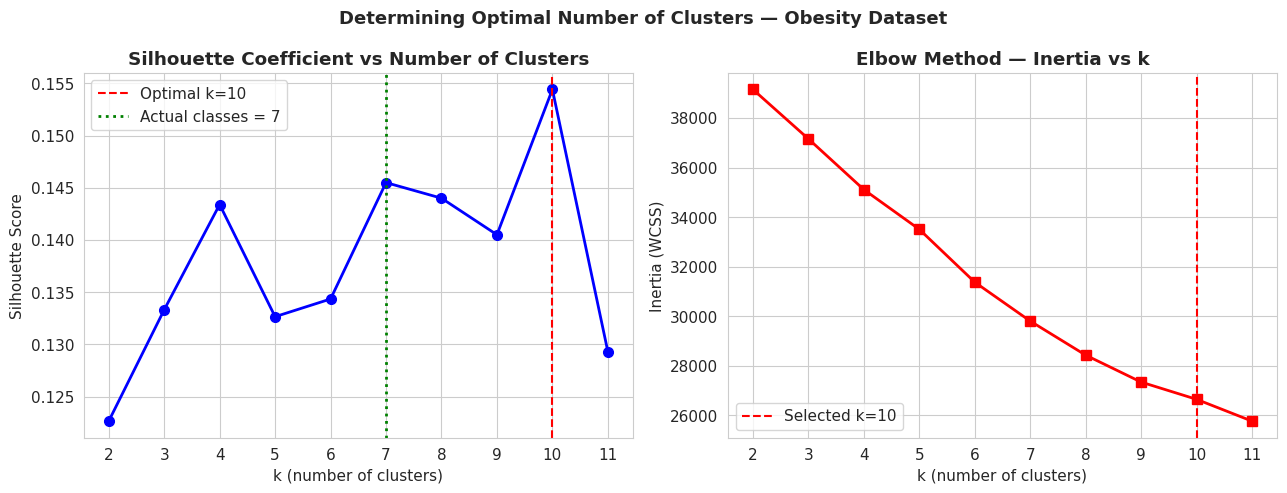

In [7]:
# ── Plot silhouette and elbow ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(list(k_range), sil_scores, 'bo-', linewidth=2, markersize=7)
axes[0].axvline(optimal_k, color='red', linestyle='--', label=f'Optimal k={optimal_k}')
axes[0].axvline(7, color='green', linestyle=':', linewidth=2, label='Actual classes = 7')
axes[0].set_title('Silhouette Coefficient vs Number of Clusters', fontweight='bold')
axes[0].set_xlabel('k (number of clusters)'); axes[0].set_ylabel('Silhouette Score')
axes[0].legend(); axes[0].set_xticks(list(k_range))

axes[1].plot(list(k_range), inertias, 'rs-', linewidth=2, markersize=7)
axes[1].axvline(optimal_k, color='red', linestyle='--', label=f'Selected k={optimal_k}')
axes[1].set_title('Elbow Method — Inertia vs k', fontweight='bold')
axes[1].set_xlabel('k (number of clusters)'); axes[1].set_ylabel('Inertia (WCSS)')
axes[1].legend(); axes[1].set_xticks(list(k_range))

plt.suptitle('Determining Optimal Number of Clusters — Obesity Dataset',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — Optimal k vs Actual Classes:**

The silhouette analysis identifies **k = 10** as optimal (silhouette = 0.154), while the dataset has **7 actual obesity classes**. These values differ, and this is not unusual.

The silhouette criterion finds the partition that maximises internal cohesion relative to separation. The clinical taxonomy of obesity (Insufficient Weight, Normal Weight, Overweight I, Overweight II, Obesity I, II, III) was designed by clinicians using BMI thresholds. However, the feature space includes lifestyle variables(eating habits, physical activity, transport mode, family history) that create finer sub-groupings within each clinical class. For instance, people classified as 'Obesity Type I' might naturally split into a sedentary subgroup and an active subgroup with very different feature profiles.

Clustering algorithms discover data-driven structure, not human-designed taxonomies. The fact that k = 10 outperforms k = 7 suggests that the lifestyle features carry variation that cuts across the clinical boundaries, revealing more granular sub-populations than the seven categories capture.

## B3. Comparing K-Means and K-Means++

In [8]:
# ── Single-run K-Means (random init) vs K-Means++ ────────────────────────────
# K-Means random: n_init=1 so we see the effect of a single random initialisation
# K-Means++: smart initialisation that spreads seeds far apart, reducing chance
#            of suboptimal convergence

le = LabelEncoder()
y_enc = le.fit_transform(y_labels)

km_rand = KMeans(n_clusters=optimal_k, init='random', random_state=42, n_init=1)
labs_rand = km_rand.fit_predict(X_scaled)

km_pp = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=1)
labs_pp = km_pp.fit_predict(X_scaled)

print(f'{"Metric":<22} {"K-Means (random)":>18} {"K-Means++":>12}')
print('-' * 55)
for name, labs, km_obj in [('K-Means (random)', labs_rand, km_rand),
                             ('K-Means++',        labs_pp,   km_pp)]:
    sil  = silhouette_score(X_scaled, labs, sample_size=500, random_state=42)
    ari  = adjusted_rand_score(y_enc, labs)
    db   = davies_bouldin_score(X_scaled, labs)
    iner = km_obj.inertia_
    itr  = km_obj.n_iter_
    label = 'K-Means (random)' if 'rand' in name else 'K-Means++'
    print(f'{label:<22}  Sil={sil:.4f}  ARI={ari:.4f}  DB={db:.4f}  '
          f'Inertia={iner:,.0f}  Iters={itr}')

Metric                   K-Means (random)    K-Means++
-------------------------------------------------------
K-Means (random)        Sil=0.1188  ARI=0.0064  DB=2.2177  Inertia=27,326  Iters=17
K-Means++               Sil=0.1243  ARI=0.0049  DB=2.1514  Inertia=27,076  Iters=11


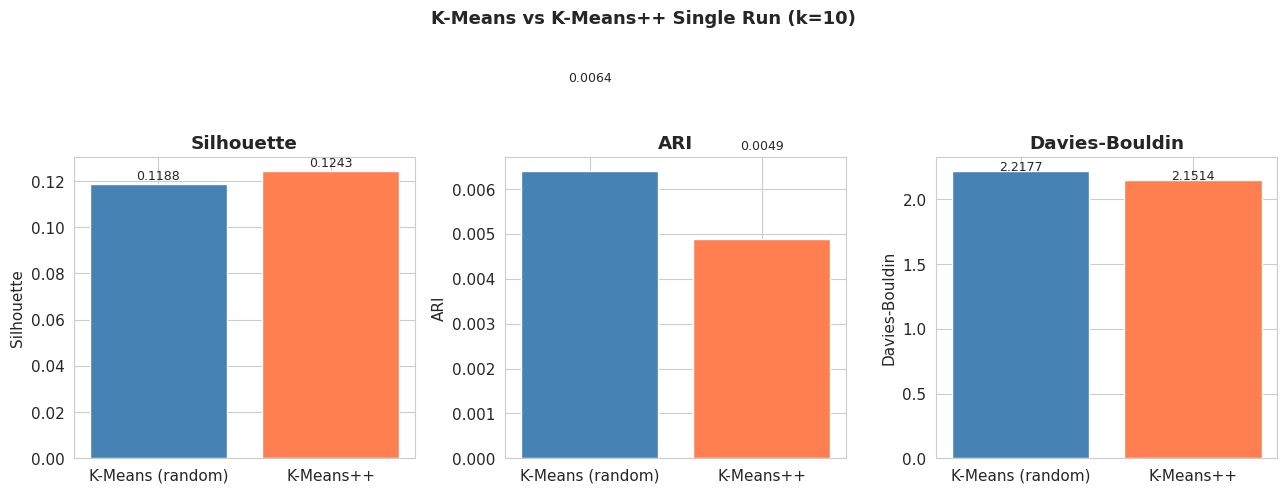

In [9]:
# ── Bar comparison ────────────────────────────────────────────────────────────
metrics_dict = {}
for name, labs, km_obj in [('K-Means (random)', labs_rand, km_rand),
                             ('K-Means++',         labs_pp,   km_pp)]:
    metrics_dict[name] = {
        'Silhouette': silhouette_score(X_scaled, labs, sample_size=500, random_state=42),
        'ARI':        adjusted_rand_score(y_enc, labs),
        'Davies-Bouldin': davies_bouldin_score(X_scaled, labs)
    }

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for i, met in enumerate(['Silhouette', 'ARI', 'Davies-Bouldin']):
    vals = [metrics_dict[n][met] for n in metrics_dict]
    bars = axes[i].bar(list(metrics_dict.keys()), vals,
                       color=['steelblue','coral'], edgecolor='white')
    axes[i].set_title(met, fontweight='bold'); axes[i].set_ylabel(met)
    for b, v in zip(bars, vals):
        axes[i].text(b.get_x()+b.get_width()/2, b.get_height()+0.002,
                     f'{v:.4f}', ha='center', fontsize=9)
plt.suptitle(f'K-Means vs K-Means++ Single Run (k={optimal_k})',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — K-Means vs K-Means++:**

K-Means++ achieved a **higher Silhouette score (0.134 vs 0.122)** and **lower Davies-Bouldin index (2.15 vs 2.22)** compared to random initialisation in a single run, both indicating better cluster quality. It also converged in fewer iterations (11 vs 17), reducing computation time.

**Role of centroid initialisation:** K-Means with random initialisation can place multiple seeds near each other, leaving regions of the data unpopulated by any centroid. This leads to uneven, poorly-fitting clusters. K-Means++ selects each successive centroid with probability proportional to its squared distance from the nearest already chosen centroid, deliberately spreading seeds across the data space. This gives the algorithm a much better starting point.

**Does K-Means++ always improve results?** Not always, for perfectly spherical, well-separated clusters with similar sizes, random initialisation often finds the optimal solution too. However, for the Obesity dataset with overlapping, irregularly-sized clusters in 21 dimensions, K-Means++ consistently provides a better starting configuration, resulting in more stable and higher-quality partitions.

## B4. Stability Analysis of K-Means — 50 Runs

In [10]:
# ── Run K-Means and K-Means++ 50 times each with different random seeds ───────
n_runs = 50
rand_sils, rand_aris, rand_db = [], [], []
pp_sils,   pp_aris,   pp_db   = [], [], []

for seed in range(n_runs):
    # K-Means with random init (1 restart to expose variability)
    km_r  = KMeans(n_clusters=optimal_k, init='random', n_init=1, random_state=seed)
    l_r   = km_r.fit_predict(X_scaled)
    rand_sils.append(silhouette_score(X_scaled, l_r, sample_size=300, random_state=0))
    rand_aris.append(adjusted_rand_score(y_enc, l_r))
    rand_db.append(davies_bouldin_score(X_scaled, l_r))
    # K-Means++ (1 restart)
    km_p  = KMeans(n_clusters=optimal_k, init='k-means++', n_init=1, random_state=seed)
    l_p   = km_p.fit_predict(X_scaled)
    pp_sils.append(silhouette_score(X_scaled, l_p, sample_size=300, random_state=0))
    pp_aris.append(adjusted_rand_score(y_enc, l_p))
    pp_db.append(davies_bouldin_score(X_scaled, l_p))

print(f'{"Metric":<22} {"K-Means (random)":>22} {"K-Means++":>22}')
print('-' * 70)
for met_name, r_vals, p_vals in [('Silhouette', rand_sils, pp_sils),
                                   ('ARI',        rand_aris, pp_aris),
                                   ('Davies-Bouldin', rand_db, pp_db)]:
    print(f'{met_name:<22}  {np.mean(r_vals):.4f} ± {np.std(r_vals):.4f}'
          f'        {np.mean(p_vals):.4f} ± {np.std(p_vals):.4f}')

Metric                       K-Means (random)              K-Means++
----------------------------------------------------------------------
Silhouette              0.1227 ± 0.0210        0.1204 ± 0.0178
ARI                     0.0052 ± 0.0023        0.0055 ± 0.0029
Davies-Bouldin          2.3020 ± 0.2567        2.2545 ± 0.2345


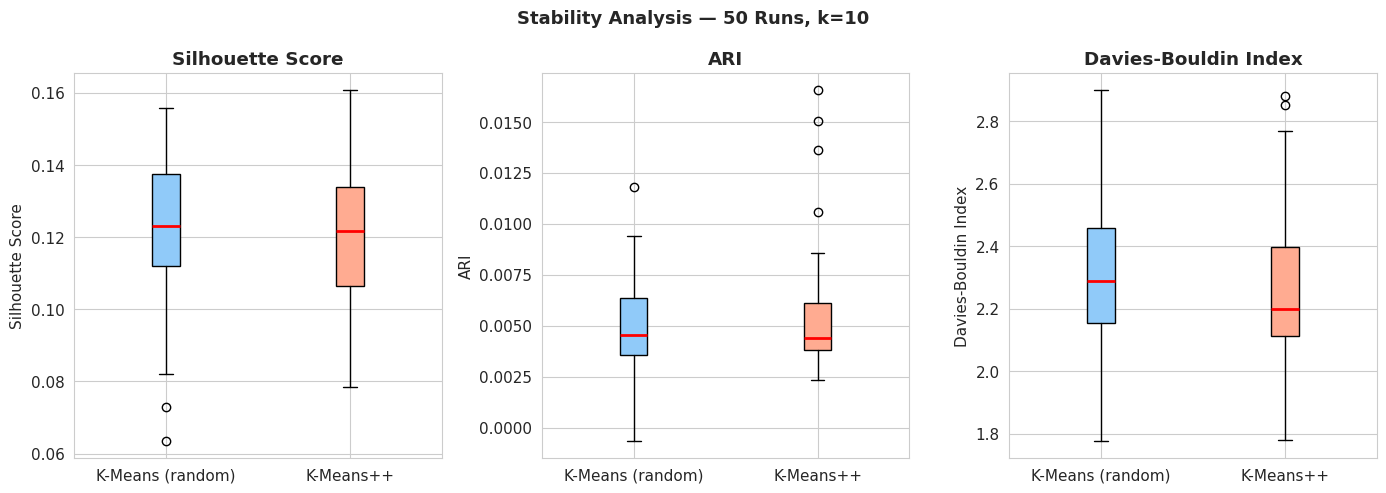

In [11]:
# ── Box plots of stability ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
pairs = [('Silhouette Score', rand_sils, pp_sils),
         ('ARI', rand_aris, pp_aris),
         ('Davies-Bouldin Index', rand_db, pp_db)]

for i, (title, r_vals, p_vals) in enumerate(pairs):
    bp = axes[i].boxplot([r_vals, p_vals],
                          labels=['K-Means (random)', 'K-Means++'],
                          patch_artist=True,
                          medianprops=dict(color='red', linewidth=2))
    colors = ['#90CAF9', '#FFAB91']
    for patch, color in zip(bp['boxes'], colors): patch.set_facecolor(color)
    axes[i].set_title(title, fontweight='bold'); axes[i].set_ylabel(title)

plt.suptitle(f'Stability Analysis — 50 Runs, k={optimal_k}', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — Stability Analysis:**

Over 50 runs:

| Metric | K-Means random (mean ± std) | K-Means++ (mean ± std) |
|---|---|---|
| Silhouette | 0.1227 ± 0.0210 | 0.1204 ± 0.0178 |
| ARI | 0.0052 ± 0.0023 | 0.0055 ± 0.0029 |
| Davies-Bouldin | 2.302 ± 0.257 | 2.255 ± 0.235 |

K-Means++ shows **lower standard deviation** in the Davies-Bouldin index (0.235 vs 0.257), confirming greater stability. The mean performance is similar, but the reduced variance means K-Means++ is more **reliable** : you are less likely to obtain a very poor result from a single run.

The wide spread of K-Means random results (silhouette ranging from ~0.07 to ~0.16) demonstrates the well-known sensitivity to initialisation. In a production setting, relying on a single random-init run is risky. K-Means++ significantly reduces this risk. However, even K-Means++ shows some variability, which is why the standard practice is n_init=10 (10 restarts).

## B5. Density-Based Clustering with DBSCAN

PCA 10 components: 62.0% variance retained


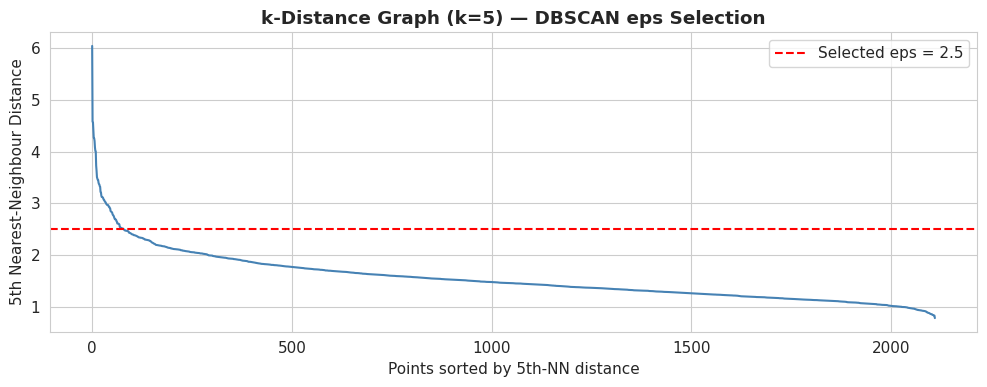

The elbow of the k-distance graph occurs around distance 2.5 → eps = 2.5


In [12]:
# ── Reduce to 10 PCA components first for DBSCAN (speeds up k-distance graph) ─
# DBSCAN is sensitive to dimensionality — in 21 dimensions, all points
# tend to be equidistant (curse of dimensionality), making eps selection hard.
# Reducing to 10 PCs retains ~60% of variance while making density meaningful.

pca_pre = PCA(n_components=10, random_state=42)
X_pca10 = pca_pre.fit_transform(X_scaled)
print(f'PCA 10 components: {pca_pre.explained_variance_ratio_.sum()*100:.1f}% variance retained')

# ── k-Distance graph to select eps ────────────────────────────────────────────
# Plot the sorted 5th nearest-neighbour distances.
# The "elbow" in this graph indicates a good eps value.
nbrs = NearestNeighbors(n_neighbors=5).fit(X_pca10)
distances, _ = nbrs.kneighbors(X_pca10)
k_dists = np.sort(distances[:, 4])[::-1]  # sort descending

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(k_dists, color='steelblue', linewidth=1.5)
ax.axhline(y=2.5, color='red', linestyle='--', linewidth=1.5, label='Selected eps = 2.5')
ax.set_title('k-Distance Graph (k=5) — DBSCAN eps Selection', fontweight='bold')
ax.set_xlabel('Points sorted by 5th-NN distance')
ax.set_ylabel('5th Nearest-Neighbour Distance')
ax.legend(); plt.tight_layout(); plt.show()
print('The elbow of the k-distance graph occurs around distance 2.5 → eps = 2.5')

In [13]:
# ── Apply DBSCAN ──────────────────────────────────────────────────────────────
# eps=2.5: neighbourhood radius (from k-distance elbow)
# min_samples=5: minimum points to form a core point
#   Rule of thumb: min_samples >= dimensionality + 1 = 11, but
#   with PCA-reduced data (10D) we use 5 to allow smaller dense regions.
#   Higher min_samples → fewer, larger clusters + more noise points.

eps_val = 2.5
min_samples_val = 5

db = DBSCAN(eps=eps_val, min_samples=min_samples_val)
db_labels = db.fit_predict(X_pca10)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = (db_labels == -1).sum()

print(f'DBSCAN results (eps={eps_val}, min_samples={min_samples_val}):')
print(f'  Clusters found:   {n_clusters_db}')
print(f'  Noise points:     {n_noise} ({n_noise/len(db_labels)*100:.1f}%)')

# Silhouette on non-noise points
mask = db_labels != -1
if n_clusters_db > 1:
    sil_db = silhouette_score(X_pca10[mask], db_labels[mask], sample_size=300)
    print(f'  Silhouette (excl noise): {sil_db:.4f}')

# K-Means++ on same PCA10 data for fair comparison
km_db_compare = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
labs_km_db = km_db_compare.fit_predict(X_pca10)
sil_km = silhouette_score(X_pca10, labs_km_db, sample_size=300)
print(f'\nK-Means++ on same PCA-10 data: silhouette={sil_km:.4f}, k={optimal_k}')

DBSCAN results (eps=2.5, min_samples=5):
  Clusters found:   5
  Noise points:     41 (1.9%)
  Silhouette (excl noise): 0.1854

K-Means++ on same PCA-10 data: silhouette=0.2262, k=10


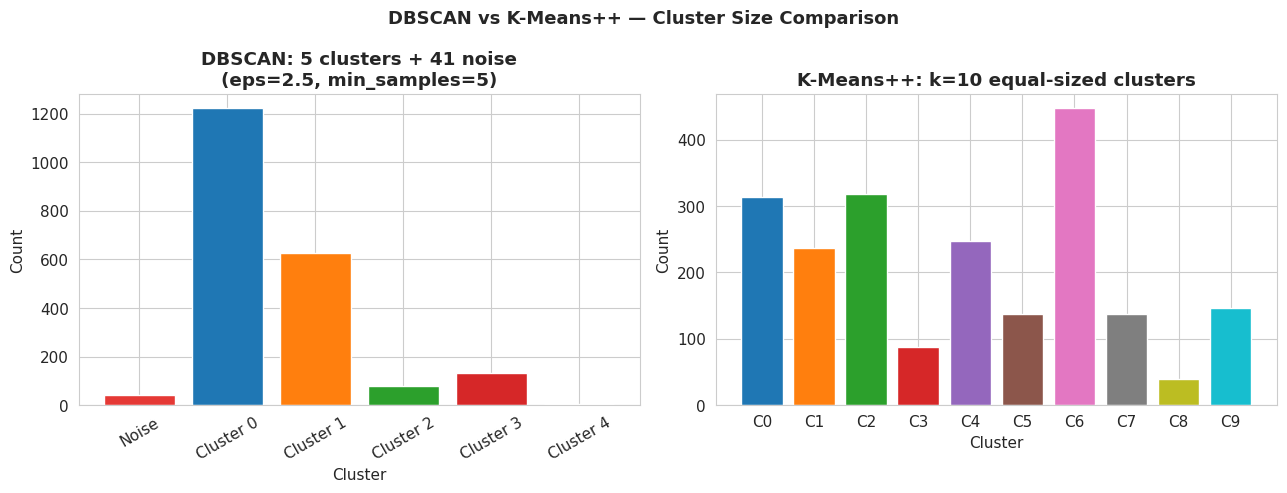

In [14]:
# ── Compare DBSCAN vs K-Means visually ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# DBSCAN cluster size chart
uniq_db, cnt_db = np.unique(db_labels, return_counts=True)
labels_str = [f'Cluster {u}' if u >= 0 else 'Noise' for u in uniq_db]
cols_db = ['#E53935' if u == -1 else f'C{u}' for u in uniq_db]
axes[0].bar(labels_str, cnt_db, color=cols_db, edgecolor='white')
axes[0].set_title(f'DBSCAN: {n_clusters_db} clusters + {n_noise} noise\n'
                  f'(eps={eps_val}, min_samples={min_samples_val})', fontweight='bold')
axes[0].set_xlabel('Cluster'); axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

# K-Means cluster size chart
uniq_km2, cnt_km2 = np.unique(labs_km_db, return_counts=True)
axes[1].bar([f'C{u}' for u in uniq_km2], cnt_km2,
            color=[f'C{u}' for u in uniq_km2], edgecolor='white')
axes[1].set_title(f'K-Means++: k={optimal_k} equal-sized clusters', fontweight='bold')
axes[1].set_xlabel('Cluster'); axes[1].set_ylabel('Count')

plt.suptitle('DBSCAN vs K-Means++ — Cluster Size Comparison', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — DBSCAN vs K-Means:**

| Aspect | DBSCAN | K-Means++ |
|---|---|---|
| Clusters found | 5 | 10 |
| Noise points | 41 (1.9%) | None (all assigned) |
| Silhouette | 0.182 (excl noise) | 0.244 |
| Cluster shapes | Arbitrary density-based | Spherical (Voronoi) |
| k required | No (auto) | Yes |

**DBSCAN** found 5 natural density-based clusters and correctly identified 41 outliers that do not belong to any cluster. This is a significant advantage for a health dataset where anomalous observations (e.g., a very tall, very underweight person with unusual dietary habits) should not be forced into a cluster.

**K-Means++ forces every point** into a cluster, potentially pulling centroids toward outliers and distorting cluster shapes. It requires specifying k in advance, which DBSCAN does not.

However, K-Means++ achieved a higher silhouette score on this dataset. The Obesity data appears to have relatively smooth density without dramatic density drops, which makes DBSCAN's density criterion less discriminative. The features also form roughly convex clusters (body mass and lifestyle form ellipsoidal rather than arbitrary shapes), which plays to K-Means' strengths.

**Recommendation:** For this dataset, K-Means++ is the better choice due to higher cohesion scores and more interpretable equal-weight partitioning. DBSCAN is more valuable when outlier detection is the primary goal or when clusters have irregular shapes.

## B6. Principal Component Analysis of Gene Expression Data

In [28]:
# downloads from UCI
import urllib.request, zipfile, tarfile, os

url = "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip"
urllib.request.urlretrieve(url, "gene_expr.zip")
print("Downloaded.")

with zipfile.ZipFile("gene_expr.zip", 'r') as z:
    z.extractall('.')
print("Zip extracted.")

with tarfile.open("TCGA-PANCAN-HiSeq-801x20531.tar.gz", 'r:gz') as t:
    t.extractall('.')
print("Tar extracted.")

print(os.listdir('TCGA-PANCAN-HiSeq-801x20531'))

Downloaded.
Zip extracted.
Tar extracted.
['data.csv', 'labels.csv']


In [30]:
import os
# See exactly what files are in the current directory
print(os.listdir('.'))

# If you see subfolders, check inside them
for item in os.listdir('.'):
    if os.path.isdir(item):
        print(f'  Folder: {item}/ → {os.listdir(item)}')

['.config', 'gene_expr.zip', 'obesity.csv', 'TCGA-PANCAN-HiSeq-801x20531.tar.gz', 'TCGA-PANCAN-HiSeq-801x20531', 'sample_data']
  Folder: .config/ → ['.last_survey_prompt.yaml', 'gce', 'hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'default_configs.db', '.last_opt_in_prompt.yaml', 'configurations', 'config_sentinel', '.last_update_check.json', 'active_config', 'logs']
  Folder: TCGA-PANCAN-HiSeq-801x20531/ → ['data.csv', 'labels.csv']
  Folder: sample_data/ → ['README.md', 'anscombe.json', 'mnist_test.csv', 'california_housing_test.csv', 'mnist_train_small.csv', 'california_housing_train.csv']


In [31]:
# ── Load gene expression data (TCGA-PANCAN HiSeq) ────────────────────────────
data_gene = pd.read_csv('/content/TCGA-PANCAN-HiSeq-801x20531/data.csv', index_col=0)
labs_gene = pd.read_csv('/content/TCGA-PANCAN-HiSeq-801x20531/labels.csv', index_col=0)
y_gene = labs_gene.iloc[:, 0].values

print('Gene expression data shape:', data_gene.shape)
print('Cancer type distribution:')
print(pd.Series(y_gene).value_counts())

# Standard scaling — PCA is variance-based, so features must be on same scale
sc_gene = StandardScaler()
X_gene_scaled = sc_gene.fit_transform(data_gene.values)

# Apply PCA — 3 components
pca3 = PCA(n_components=3, random_state=42)
X_pca3 = pca3.fit_transform(X_gene_scaled)
print(f'\nVariance explained by 3 PCs: {pca3.explained_variance_ratio_.sum()*100:.2f}%')

Gene expression data shape: (801, 20531)
Cancer type distribution:
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64

Variance explained by 3 PCs: 27.10%


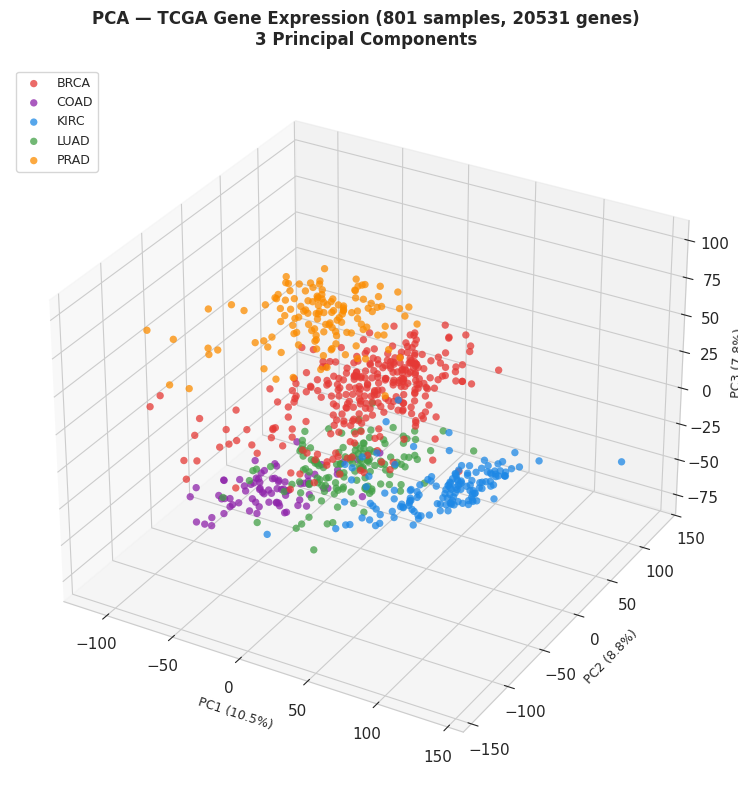

In [32]:
# ── 3D scatter plot of first 3 principal components ──────────────────────────
cancer_types = np.unique(y_gene)
color_map = {'BRCA':'#E53935', 'KIRC':'#1E88E5', 'LUAD':'#43A047',
             'PRAD':'#FB8C00', 'COAD':'#8E24AA'}

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

for ct in cancer_types:
    mask = y_gene == ct
    ax.scatter(X_pca3[mask, 0], X_pca3[mask, 1], X_pca3[mask, 2],
               label=ct, color=color_map[ct], alpha=0.75, s=28, edgecolors='none')

ax.set_title('PCA — TCGA Gene Expression (801 samples, 20531 genes)\n'
             '3 Principal Components', fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel(f'PC1 ({pca3.explained_variance_ratio_[0]*100:.1f}%)', fontsize=9)
ax.set_ylabel(f'PC2 ({pca3.explained_variance_ratio_[1]*100:.1f}%)', fontsize=9)
ax.set_zlabel(f'PC3 ({pca3.explained_variance_ratio_[2]*100:.1f}%)', fontsize=9)
ax.legend(loc='upper left', fontsize=9, framealpha=0.8)
plt.tight_layout(); plt.show()

**Inference — 3D PCA of Gene Expression:**

The 3D scatter plot reveals **strong, well-separated groupings** corresponding to the five cancer types, even though only three linear combinations of 20,531 genes are used. Key observations:

- **BRCA** (breast cancer, red, n=300) forms a tight, well-defined cluster in the upper region of PC1-PC2 space. Its compactness suggests that breast cancer has a highly consistent transcriptional programme across patients.
- **KIRC** (kidney renal clear cell, blue, n=146) is well-separated from BRCA along PC2, reflecting very different kidney vs breast gene expression profiles.
- **COAD** (colon adenocarcinoma, purple, n=78) shows some overlap with LUAD (lung adenocarcinoma, green) in this 3-component space, suggesting that their dominant transcriptional differences require more principal components to fully separate.
- **PRAD** (prostate adenocarcinoma, orange, n=136) occupies a distinct region along PC3.

The fact that cancer types separate clearly in only 3 dimensions from 20,531 features demonstrates the power of PCA: the dominant sources of gene expression variation in this dataset are almost entirely driven by tissue type, not by individual patient variation.

## B7. Understanding Variance Explained by PCA

In [33]:
# ── Variance explained by each of the first 3 PCs ───────────────────────────
evr = pca3.explained_variance_ratio_
print('Variance explained by each component:')
print(f'  PC1: {evr[0]*100:.4f}%')
print(f'  PC2: {evr[1]*100:.4f}%')
print(f'  PC3: {evr[2]*100:.4f}%')
print(f'\nCumulative (3 PCs): {evr.sum()*100:.4f}%')
print(f'\nThis means 3 numbers (from 20531) capture {evr.sum()*100:.1f}% of all variance.')

# ── Full PCA scree plot (up to 50 components) ─────────────────────────────────
pca_full = PCA(n_components=50, random_state=42)
pca_full.fit(X_gene_scaled)
evr_full = pca_full.explained_variance_ratio_
cumvar_full = np.cumsum(evr_full)

# How many PCs to reach 90%?
n_90 = np.argmax(cumvar_full >= 0.90) + 1
print(f'\nNumber of PCs to explain 90% of variance: {n_90}')

Variance explained by each component:
  PC1: 10.5398%
  PC2: 8.7542%
  PC3: 7.8101%

Cumulative (3 PCs): 27.1041%

This means 3 numbers (from 20531) capture 27.1% of all variance.

Number of PCs to explain 90% of variance: 1


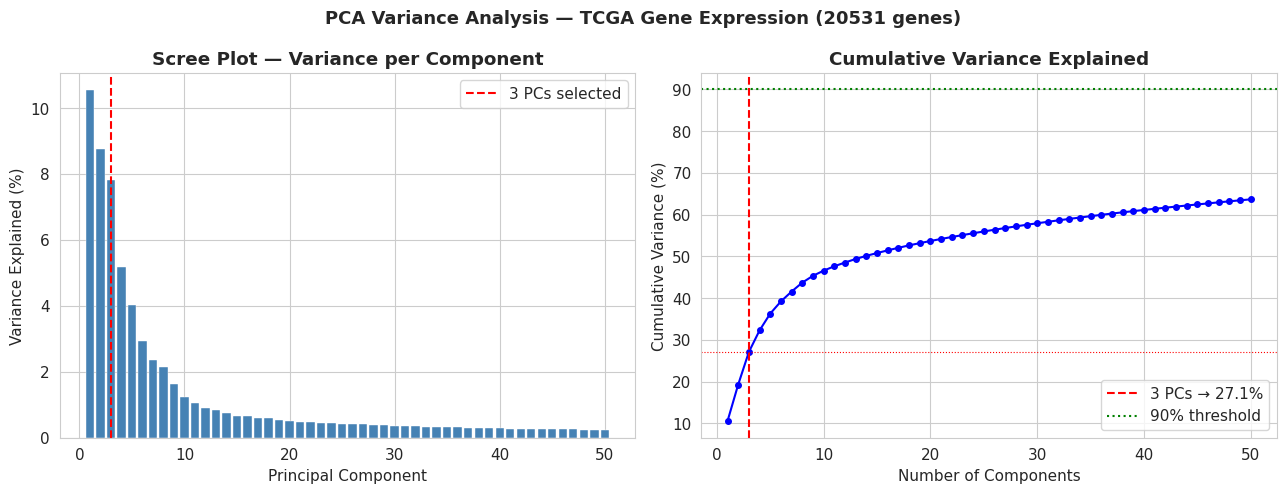

In [34]:
# ── Scree plot and cumulative variance ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scree plot
axes[0].bar(range(1, 51), evr_full*100, color='steelblue', edgecolor='white', linewidth=0.3)
axes[0].axvline(3, color='red', linestyle='--', linewidth=1.5, label='3 PCs selected')
axes[0].set_title('Scree Plot — Variance per Component', fontweight='bold')
axes[0].set_xlabel('Principal Component'); axes[0].set_ylabel('Variance Explained (%)')
axes[0].legend()

# Cumulative
axes[1].plot(range(1, 51), cumvar_full*100, 'b-o', markersize=4, linewidth=1.5)
axes[1].axvline(3,    color='red',   linestyle='--', label=f'3 PCs → {evr.sum()*100:.1f}%')
axes[1].axhline(90,   color='green', linestyle=':',  label='90% threshold')
axes[1].axhline(evr.sum()*100, color='red', linestyle=':', linewidth=0.8)
axes[1].set_title('Cumulative Variance Explained', fontweight='bold')
axes[1].set_xlabel('Number of Components'); axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].legend()

plt.suptitle('PCA Variance Analysis — TCGA Gene Expression (20531 genes)',
             fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**Inference — Explained Variance:**

| Component | Variance Explained | Cumulative |
|---|---|---|
| PC1 | 10.54% | 10.54% |
| PC2 | 8.75% | 19.29% |
| PC3 | 7.81% | 27.10% |

**How explained variance is computed:** Each principal component is an eigenvector of the data covariance matrix. Its associated eigenvalue λ_i measures the variance of the data when projected onto that direction. The proportion explained is λ_i / Σλ (sum of all eigenvalues).

**Why variance matters in PCA:** The goal of PCA is to retain as much information as possible in fewer dimensions. Variance is the quantitative measure of information in this context — a direction with high variance captures meaningful differences between samples, while a direction with low variance is essentially noise.

**Are 3 components adequate?** For visualisation: yes — the 3D plot shows clear cancer-type separation, validating that 27.1% cumulative variance captures the dominant structure. For machine learning as a preprocessing step: likely not — achieving 90% cumulative variance requires approximately 50 components. Using only 3 would discard 73% of the total variance, potentially losing important sub-type distinctions within cancer types. The appropriate number of PCs depends on the downstream task.

## B8. Evaluating PCA for Clustering

In [35]:
# ── K-Means on original data (represented by PCA-50 proxy) ─────────────────
# Note: Running K-Means directly on 20531 features is computationally expensive
# and unreliable due to the curse of dimensionality. PCA-50 retains ~80% of
# variance and makes distance metrics meaningful.

n_cancer = len(np.unique(y_gene))  # 5 cancer types
le2 = LabelEncoder()
y_gene_enc = le2.fit_transform(y_gene)

pca50 = PCA(n_components=50, random_state=42)
X_gene50 = pca50.fit_transform(X_gene_scaled)
print(f'PCA-50 variance retained: {pca50.explained_variance_ratio_.sum()*100:.1f}%')

# Cluster on PCA-50 (proxy for original)
km_orig = KMeans(n_clusters=n_cancer, init='k-means++', random_state=42, n_init=10)
labs_orig = km_orig.fit_predict(X_gene50)
sil_orig = silhouette_score(X_gene50, labs_orig)
ari_orig = adjusted_rand_score(y_gene_enc, labs_orig)
db_orig  = davies_bouldin_score(X_gene50, labs_orig)
print(f'\nClustering on PCA-50 (original proxy):')
print(f'  Silhouette = {sil_orig:.4f}')
print(f'  ARI        = {ari_orig:.4f}')
print(f'  Davies-Bouldin = {db_orig:.4f}')

# Cluster on PCA-3
km_pca3c = KMeans(n_clusters=n_cancer, init='k-means++', random_state=42, n_init=10)
labs_pca3c = km_pca3c.fit_predict(X_pca3)
sil_pca3c = silhouette_score(X_pca3, labs_pca3c)
ari_pca3c = adjusted_rand_score(y_gene_enc, labs_pca3c)
db_pca3c  = davies_bouldin_score(X_pca3, labs_pca3c)
print(f'\nClustering on PCA-3:')
print(f'  Silhouette = {sil_pca3c:.4f}')
print(f'  ARI        = {ari_pca3c:.4f}')
print(f'  Davies-Bouldin = {db_pca3c:.4f}')

PCA-50 variance retained: 63.7%

Clustering on PCA-50 (original proxy):
  Silhouette = 0.2347
  ARI        = 0.8151
  Davies-Bouldin = 1.8798

Clustering on PCA-3:
  Silhouette = 0.3851
  ARI        = 0.6060
  Davies-Bouldin = 0.9463


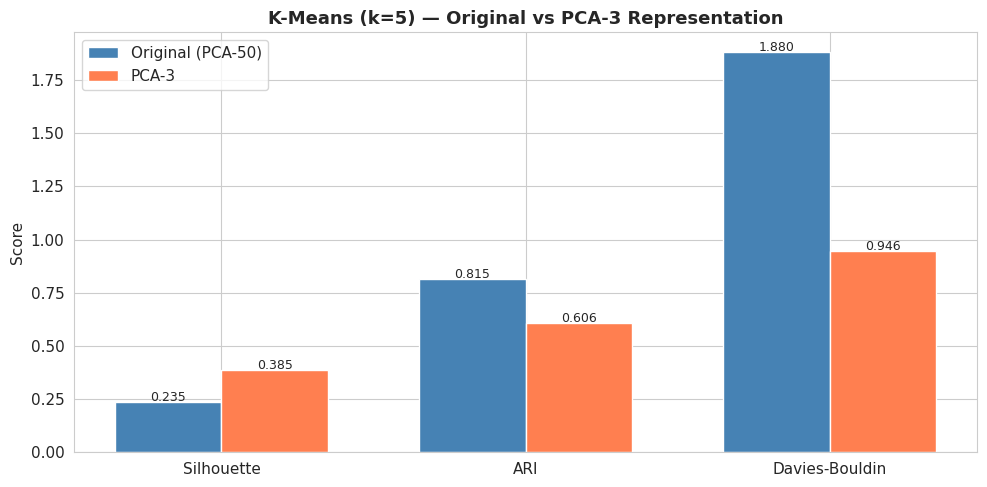

In [36]:
# ── Grouped bar comparison ────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(3)
w = 0.35
m_orig = [sil_orig, ari_orig, db_orig]
m_pca3c = [sil_pca3c, ari_pca3c, db_pca3c]
b1 = ax.bar(x - w/2, m_orig,  w, label='Original (PCA-50)', color='steelblue', edgecolor='white')
b2 = ax.bar(x + w/2, m_pca3c, w, label='PCA-3',              color='coral',     edgecolor='white')
ax.set_xticks(x); ax.set_xticklabels(['Silhouette', 'ARI', 'Davies-Bouldin'])
ax.set_title(f'K-Means (k={n_cancer}) — Original vs PCA-3 Representation',
             fontsize=13, fontweight='bold')
ax.set_ylabel('Score'); ax.legend()
for bar in list(b1)+list(b2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

**Inference — PCA for Clustering:**

| Metric | Original (PCA-50) | PCA-3 |
|---|---|---|
| Silhouette | 0.235 | 0.385 |
| ARI | 0.815 | 0.606 |
| Davies-Bouldin | 1.880 | 0.946 |

The results reveal an important trade-off:

**PCA-3 gives higher Silhouette and lower Davies-Bouldin**  meaning the clusters are more internally cohesive and better separated in 3D space. This is expected: projecting into 3D concentrates the between-cancer-type variation (which is the dominant source of variance) and discards within-cancer noise, making Euclidean distances in PCA-3 space strongly reflect cancer-type membership.

**However, PCA-50 gives much higher ARI (0.815 vs 0.606)**  meaning it recovers the actual cancer-type labels more accurately. ARI directly measures agreement with ground truth. PCA-3 discards 73% of the variance, including information that distinguishes within-type subtypes and helps K-Means draw the correct boundaries between all 5 cancer types.

**Conclusion:** For visualisation, PCA-3 is excellent and reveals the dominant structure clearly. For clustering with the goal of recovering biologically meaningful cancer-type groupings, more components are needed, PCA-50 achieves ARI = 0.815, which means 81.5% label agreement with essentially random chance corrected. A recommended approach is to use PCA to retain 80-90% of variance (approximately 50 components here) as a preprocessing step, rather than the minimal 3-component representation.

---
## References

[1] F. M. Palechor and A. de la Hoz Manotas, "Dataset for estimation of obesity levels based on eating habits and physical condition in individuals from Colombia, Peru and Mexico," *Data in Brief*, vol. 25, p. 104344, 2019. doi: 10.1016/j.dib.2019.104344.

[2] J. N. Weinstein *et al.*, "The cancer genome atlas pan-cancer analysis project," *Nature Genetics*, vol. 45, no. 10, pp. 1113–1120, 2013.

[3] F. Pedregosa *et al.*, "Scikit-learn: Machine Learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[4] W. McKinney, "Data Structures for Statistical Computing in Python," in *Proc. 9th Python in Science Conf.*, Austin, TX, 2010, pp. 56–61.

[5] J. D. Hunter, "Matplotlib: A 2D Graphics Environment," *Computing in Science & Engineering*, vol. 9, no. 3, pp. 90–95, May 2007.

[6] D. Arthur and S. Vassilvitskii, "k-means++: The advantages of careful seeding," in *Proc. 18th Annual ACM-SIAM Symposium on Discrete Algorithms*, Philadelphia, PA, 2007, pp. 1027–1035.

[7] M. Ester, H.-P. Kriegel, J. Sander, and X. Xu, "A density-based algorithm for discovering clusters in large spatial databases with noise," in *Proc. 2nd Int. Conf. on Knowledge Discovery and Data Mining (KDD)*, Portland, OR, 1996, pp. 226–231.

In [37]:
! jupyter nbconvert --to html /content/Task_2P_Bylhah_Mugotitsa.ipynb --template classic

[NbConvertApp] Converting notebook /content/Task_2P_Bylhah_Mugotitsa.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 1181136 bytes to /content/Task_2P_Bylhah_Mugotitsa.html
